![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 03 | Evaluate — the Report

*Project 3 — AI Product: From Model to Product*

**Student:** Gabriel Gomes

**Track:** LLM

**Data:** Criterion Collection

---
## Setup

In [1]:
import sys
sys.path.append("..")          # so `src` is importable from inside notebooks/
sys.path.append("../src")      # the src scripts import each other by bare name

import json

import pandas as pd

from src.first_look import load_tables
from src.eval_checks import prepare_catalogue, filter_catalogue
from src.prepare_documents import format_citation
from src.functions import *

pd.set_option("display.max_colwidth", 200)

---
## 1. The question

**The user and the decision.** The product is a guide to the Criterion Collection for a film fan or cineclub organizer who is deciding what to watch or program next, and who wants a recommendation they can trust rather than a generic "best films" list. They type a request in plain language, such as "a tense 1970s political thriller". They get about three films from the Collection, each with a reason and citations to its Wikipedia article and TMDB record. If the sources cannot answer, it says so.

**The metric.** I score 30 questions written for this user: 25 that the data can answer and 5 that it cannot. An automatic check decides each one, and for the recommendation questions precision counts the share of picks that are in the Collection and meet the stated constraints (decade, genre, country, runtime). The costliest mistake is a wrong answer, such as recommending a film that is not in the Collection, because the user may plan a screening around it. An answer with no source comes next, since the user cannot verify it. An unnecessary refusal costs least, as long as the system still refuses all five unanswerable questions.

**The baseline.** The score to beat is the same model with no retrieval and no tools. It passed the automatic checks on 11 of the 25 answerable questions (44%), had a precision of 0.70, named 8 titles out of 41 that are not in the Collection, cited nothing, wrongly refused 3 of the 25 answerable questions, and refused 4 of the 5 unanswerable ones.

---
## 2. The final evaluation

**What is being evaluated.** The final version answers a question in one of two ways. A first call to the LLM extracts any hard constraints (years, genre, country, director, runtime) and classifies the question.

- **Retrieval, for most questions.** Local `all-MiniLM-L6-v2` embeddings and BM25 keyword search are merged to find 40 passages from the Collection's Wikipedia articles and TMDB records that meet the constraints. A second call answers only from those passages and cites them, and each film it names is checked against the catalog.
- **The catalog tool, for lists and counts on catalog fields.** A read-only lookup answers from the catalog rows and cites them, with no second call.

**The versions.** Each row in the table below adds one thing to the row above it, and all of them run on all 30 questions. The final version is the last row. All the numbers here come from saved runs, so re-running this notebook makes no new calls.

In [2]:
collection, catalog, settings = load_pipeline()          # the index and the settings saved in notebook 02
cat = prepare_catalogue(load_tables()[0])
eval_set = pd.read_csv(ROOT / "data" / "evaluation_set.csv")
frozen = freeze_filters(eval_set)
extended = extend_filters(frozen, eval_set)
baseline_answers, baseline_log = run_baseline(eval_set)

final_run = run_version("ladder_tool", eval_set, collection, frozen=extended, catalog=catalog, **settings)   # saved and reused
baseline_run = baseline_as_run(baseline_log)
final = evaluate(final_run, eval_set, cat, "final")
baseline = evaluate(baseline_run, eval_set, cat, "baseline")
print(f"{len(eval_set)} questions: {(eval_set['answerable'] == 1).sum()} answerable, {(eval_set['answerable'] == 0).sum()} the data cannot answer")
print("final settings:", settings)

30 questions: 25 answerable, 5 the data cannot answer
final settings: {'k': 40, 'runtime_header': True, 'firm_picks': True, 'hybrid': True, 'tool': True}


In [3]:
versions = {f"k = {k}": (f"catalog_k{k}", frozen, {"k": k}) for k in (5, 10, 20, 40)}
versions |= {"+ runtime":       ("ladder_runtime", extended, {"k": 40, "runtime_header": True}),
             "+ firmer prompt": ("ladder_firm", extended, {"k": 40, "runtime_header": True, "firm_picks": True}),
             "+ hybrid search": ("ladder_hybrid", extended, {"k": 40, "runtime_header": True, "firm_picks": True, "hybrid": True}),
             "+ catalog tool":  ("ladder_tool", extended, settings)}
scored = {name: evaluate(run_version(run, eval_set, collection, frozen=filters, catalog=catalog, **options), eval_set, cat, run)
          for name, (run, filters, options) in versions.items()}       # saved runs: no new calls

comparison = pd.DataFrame({name: version_summary(df, eval_set) for name, df in {"LLM alone": baseline, **scored}.items()}).T
comparison.loc["LLM alone", ["retrieval_hit", "list_coverage"]] = None     # no retrieval to measure
comparison.drop(columns=["mean_seconds", "input_tokens"]).round(4)

,retrieval_hit,list_coverage,citation_hit,auto_pass,pick_precision,titles_named,titles_outside,false_refusal,refused_unanswerable,total_cost_usd
LLM alone,NaN,NaN,0.0000,0.44,0.6970,41.0,8.0,0.12,0.8,0.0098
k = 5,0.7059,0.2167,0.7059,0.32,0.4848,20.0,0.0,0.36,1.0,0.0083
k = 10,0.7647,0.4083,0.7059,0.40,0.6364,25.0,0.0,0.28,1.0,0.0124
k = 20,0.7647,0.5583,0.7059,0.48,0.7576,36.0,0.0,0.24,1.0,0.0184
k = 40,1.0000,0.6333,0.8235,0.64,0.8485,43.0,0.0,0.16,1.0,0.0308
+ runtime,1.0000,0.6333,0.8824,0.68,0.9394,45.0,0.0,0.12,1.0,0.0325
+ firmer prompt,1.0000,0.6333,0.8824,0.72,1.0000,48.0,0.0,0.12,1.0,0.0325
+ hybrid search,1.0000,0.6667,0.9412,0.80,1.0000,66.0,0.0,0.04,1.0,0.0294
+ catalog tool,1.0000,0.9583,1.0000,0.92,1.0000,77.0,0.0,0.00,1.0,0.0276


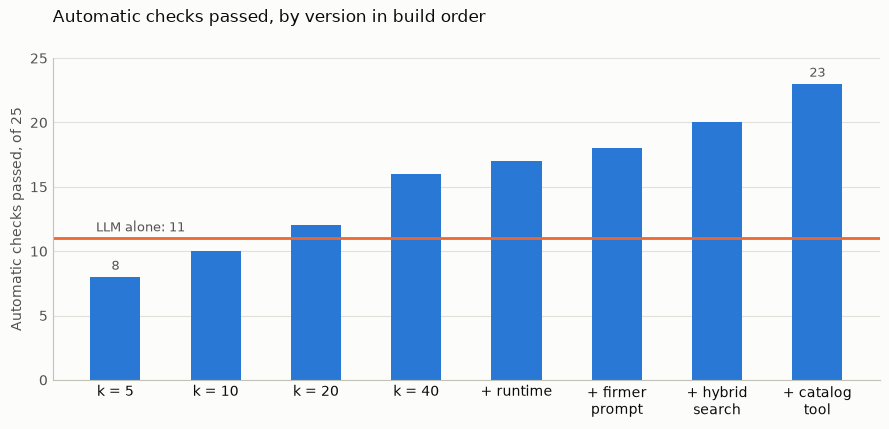

In [4]:
answerable_ids = eval_set.loc[eval_set["answerable"] == 1, "id"]
passes = [int(df.loc[df["id"].isin(answerable_ids), "auto_pass"].astype(bool).sum()) for df in scored.values()]
base_passes = int(baseline.loc[baseline["id"].isin(answerable_ids), "auto_pass"].astype(bool).sum())
plot_version_passes(list(scored), passes, base_passes, len(answerable_ids), "Automatic checks passed, by version in build order")

**Reading the chart.** Automatic passes rise at every step, from 8 to 23 of 25, and the version first beats the LLM alone at `k` = 20. The largest gains come from more context (`k` = 40), hybrid search and the catalog tool.

In [5]:
def rate(df, col, ids=None):
    """Passed and total for one yes-or-no column, on the questions in `ids` where it applies."""
    values = df.loc[df["id"].isin(ids if ids is not None else df["id"]), col].dropna().astype(bool)
    return int(values.sum()), len(values)

unanswerable_ids = eval_set.loc[eval_set["answerable"] == 0, "id"]
routes = tool_use(final_run, eval_set)

def headline(df):
    return {"Correct (automatic checks, answerable)": rate(df, "auto_pass", answerable_ids),
            "Cited an expected source": rate(df, "source_hit", answerable_ids),
            "Refused when it should (unanswerable)": rate(df, "refused", unanswerable_ids),
            "Refused when it should not (answerable)": rate(df, "false_refusal", answerable_ids),
            "Titles named that are outside the catalog": (int(df["titles_outside"].sum()), int(df["titles_named"].sum()))}

retrieval_rows = {"Retrieval hit (expected film or director reached the model)": ("n/a", "{} of {}".format(*rate(final, "retrieval_hit", answerable_ids))),
                  "Questions on the expected route (tool or retrieval)": ("n/a", f"{routes['correct'].sum()} of {len(routes)}")}
report = pd.DataFrame({"LLM alone": {k: f"{a} of {b}" for k, (a, b) in headline(baseline).items()},
                       "Final version": {k: f"{a} of {b}" for k, (a, b) in headline(final).items()}})
report = pd.concat([pd.DataFrame(retrieval_rows, index=["LLM alone", "Final version"]).T, report])
print(f"precision on the pick questions: LLM alone {baseline['pick_precision'].dropna().mean():.2f}, final {final['pick_precision'].dropna().mean():.2f}")
report

precision on the pick questions: LLM alone 0.70, final 1.00


,LLM alone,Final version
Retrieval hit (expected film or director reached the model),n/a,17 of 17
Questions on the expected route (tool or retrieval),n/a,29 of 30
"Correct (automatic checks, answerable)",11 of 25,23 of 25
Cited an expected source,0 of 17,17 of 17
Refused when it should (unanswerable),4 of 5,5 of 5
Refused when it should not (answerable),3 of 25,0 of 25
Titles named that are outside the catalog,8 of 41,0 of 77


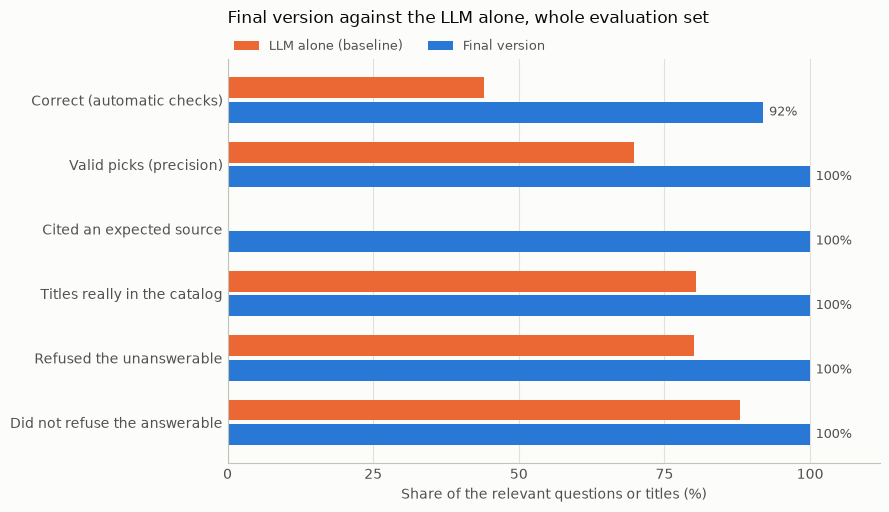

In [6]:
def share(df, col, ids, invert=False):
    passed, total = rate(df, col, ids)
    return 100 * (total - passed if invert else passed) / total

def inside_catalog(df):
    return 100 * (1 - df["titles_outside"].sum() / df["titles_named"].sum())

metrics = {"Correct (automatic checks)": lambda d: share(d, "auto_pass", answerable_ids),
           "Valid picks (precision)": lambda d: 100 * d["pick_precision"].dropna().mean(),
           "Cited an expected source": lambda d: share(d, "source_hit", answerable_ids),
           "Titles really in the catalog": inside_catalog,
           "Refused the unanswerable": lambda d: share(d, "refused", unanswerable_ids),
           "Did not refuse the answerable": lambda d: share(d, "false_refusal", answerable_ids, invert=True)}
plot_two_versions(list(metrics), [f(baseline) for f in metrics.values()], [f(final) for f in metrics.values()],
                  "Final version against the LLM alone, whole evaluation set", "Share of the relevant questions or titles (%)")

**Retrieval, answers and refusals, reported separately.**

- **Retrieval and tool use.** An expected film or director reached the model on all 17 questions that name expected sources, and 29 of the 30 questions took the expected route. The retrieval hit counts a whole film as a hit, so it is generous: question 11 below counts as a hit even though the passage it needed was not retrieved.
- **Correct answers and citations.** The final version passes 23 of 25 automatic checks against 11 for the LLM alone, and precision on the recommendation questions is 1.00 against 0.70. It cites an expected source on all 17 questions that have one, against none. It names no title outside the Collection (0 of 77), against 8 of 41, which is the costliest mistake in my framing.
- **Refusals.** It refuses all 5 unanswerable questions, against 4, and does not wrongly refuse any of the 25 answerable ones, against 3.

**Reading the chart.** The final version is ahead of the LLM alone on every measure, and it reaches 100% on all but the automatic checks. The widest gap is citation, since a model with no retrieval has no stored source to cite.

In [7]:
routes[(routes["route"] == "catalog") | ~routes["correct"]][["id", "question", "expected_route", "route", "correct"]]

,id,question,expected_route,route,correct
6,7,Which Brazilian productions or films shot in Brazil are in the Collection?,catalog,retrieval,False
7,8,Which Wim Wenders films are in the Collection?,catalog,catalog,True
13,14,How many 1970s films from Italian productions are in the Collection?,catalog,catalog,True
14,15,Which 1970s films in the Collection were made by the director of spine 11?,catalog,catalog,True


The table shows the four questions routed to the catalog, or expected there. The one miss is question 7, "Which Brazilian productions or films shot in Brazil are in the Collection?". Where a film was shot is not a catalog field, so the extractor correctly sent it to retrieval under the rule I gave it, while the expected route assumes a set computed from the catalog.

---
## 3. Where it goes wrong

**By question type.** The chart below shows where each version loses points.

In [8]:
by_type = results_by_type({"LLM alone": baseline, "Final version": final}, eval_set)
by_type

,questions,LLM alone,Final version
group,,,
Recommendations (1–6),6,3,6
Catalog sets and facts (7–11),5,1,3
Film details (12–13),2,2,2
Counts and two-step lists (14–15),2,0,2
Mood recommendations (16–20),5,3,5
Plot identification (21–23),3,2,3
Plot keyword lists (24–25),2,0,2
Data cannot answer (26–30),5,4,5


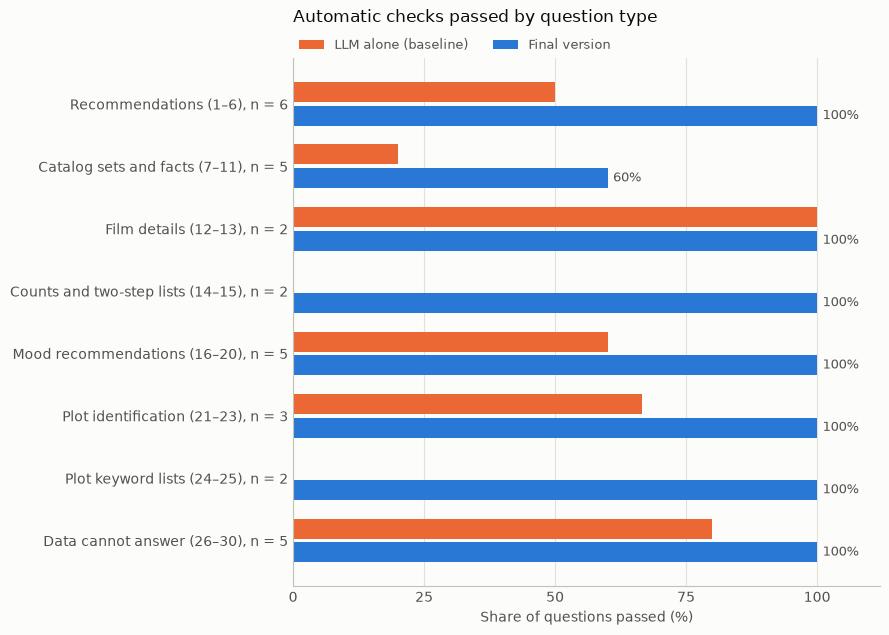

In [9]:
labels = [f"{name}, n = {row.questions}" for name, row in by_type.iterrows()]
plot_two_versions(labels, list(100 * by_type["LLM alone"] / by_type["questions"]), list(100 * by_type["Final version"] / by_type["questions"]),
                  "Automatic checks passed by question type", "Share of questions passed (%)")

**Reading the chart.** The final version passes every question in seven of the eight types. The only type below 100% is catalog sets and facts, which holds both failures. The LLM alone is weakest on what depends on knowing the catalog: sets, counts and keyword lists.

**The failures.** A failure is a tool failure if the catalog lookup answered wrongly, a retrieval failure if the evidence never reached the model, and a generation failure if the evidence reached it and the answer still failed.

In [10]:
failures = classify_failures(final, final_run, eval_set, cat, collection)
print(failures["failure"].value_counts().to_string())
failures

failure
generation    1
retrieval     1


,id,question,answer,picks,auto_detail,failure
6,7,Which Brazilian productions or films shot in Brazil are in the Collection?,The sources identify these Collection titles as Brazilian productions or films shot in Brazil:,"Frances Ha | Limite | Pixote | São Paulo, Incorporated","recall 0.38, precision 1.00, missing ['black god white devil', 'black orpheus', 'kiss of the spider woman', 'notorious', 'secret agent']",generation
10,11,Was Citizen Kane the first Criterion release?,"Yes. Citizen Kane was the Criterion Collection’s first release, on LaserDisc, in 1984.",,missing one of: [['grand illusion']],retrieval


- **Question 7, Brazilian productions or films shot in Brazil: generation failure.** The retrieved passages covered 7 of the 8 required films, yet the answer names only 3 of them (Limite, Pixote and São Paulo, Incorporated), plus Frances Ha, which is optional. Notorious, which qualifies only through its article, was not retrieved at all, because the country filter excludes it. The catalog tool does not apply either, because the question mixes a catalog field with a fact from the articles.
- **Question 11, "Was Citizen Kane the first Criterion release?": retrieval failure.** The answer is "Yes. Citizen Kane was the Criterion Collection's first release, on LaserDisc, in 1984". That is true of LaserDisc, but the first DVD was Grand Illusion, spine 1. The article's "DVD and Blu-ray" section says so, and it was not among the 40 passages, which all came from the articles on Citizen Kane and on the Collection.

**Passes that deserve a caveat.**

- **Fit is not measured.** The checks test hard constraints, so a pick can pass while being a weak recommendation. For question 2, a "slow, atmospheric" science-fiction film, the picks include Brazil, and the answer itself calls it only "atmospheric-leaning". The prompt also asks for the full number of picks when the sources hold enough films, even if the fit is not perfect.
- **Question 9 names a fourth film.** It passes with its three expected November 2026 titles plus Shadows of Forgotten Ancestors. The film's article does announce a release on 17 November 2026, so the answer is supported, and the expected answer may be incomplete.
- **A correct refusal can still cite a source.** Question 28 refuses to say what is streaming in Germany, correctly, but also cites a passage on the Criterion Channel.

**Where the product should not be trusted.**

- **Taste.** Treat its picks as a shortlist that meets the stated constraints, not as a judgment that a film has the right tone.
- **Complete lists that need article facts.** A list on director, year, country or genre comes from the catalog and is complete. A list that also depends on something in the articles, such as filming locations, can be incomplete, as question 7 shows.
- **Questions with a false or partial premise.** Question 11 shows it can confirm a premise when the correcting passage is not retrieved.
- **Anything resting on TMDB fields.** Filters and the tool are only as good as the metadata. TMDB lists Brazil as a production country for Frances Ha, for example, and 71 of the 1,920 films have no stored runtime, so a runtime limit leaves them out.
- **Live or undocumented facts.** Streaming availability, prices and future releases are not in the sources. It refused all such questions here, which is the right behavior, but it cannot answer them.
- **Films mentioned in passing.** The catalog check covers the films listed as picks. A film outside the Collection named only in the prose of an answer would not be caught.

---
## 4. Cost and speed

In [11]:
per_question = final.merge(eval_set[["id"]], on="id")
catalog_ids = routes.loc[routes["route"] == "catalog", "id"]
is_catalog = per_question["id"].isin(catalog_ids)
total_cost = per_question["cost_usd"].sum()
mean_cost = per_question["cost_usd"].mean()

pd.Series({"questions": len(per_question),
           "input tokens, total": int(per_question["input_tokens"].sum()),
           "output tokens, total": int(per_question["output_tokens"].sum()),
           "cost, total (USD)": round(total_cost, 4),
           "cost per question (USD)": round(mean_cost, 5),
           "cost per question through retrieval (USD)": round(per_question.loc[~is_catalog, "cost_usd"].mean(), 5),
           "cost per question through the catalog tool (USD)": round(per_question.loc[is_catalog, "cost_usd"].mean(), 5),
           "time per question, mean (s)": round(per_question["seconds"].mean(), 2),
           "time per question, slowest (s)": round(per_question["seconds"].max(), 2),
           "time, total (s)": round(per_question["seconds"].sum(), 1),
           "LLM alone: cost, total (USD)": round(baseline["cost_usd"].sum(), 4),
           "LLM alone: time per question, mean (s)": round(baseline["seconds"].mean(), 2),
           "1,000 questions a day, per 30-day month (USD)": round(mean_cost * 1000 * 30, 2)}).to_frame("value")

,value
questions,30.00000
"input tokens, total",230569.00000
"output tokens, total",9086.00000
"cost, total (USD)",0.02760
cost per question (USD),0.00092
cost per question through retrieval (USD),0.00101
cost per question through the catalog tool (USD),0.00009
"time per question, mean (s)",3.57000
"time per question, slowest (s)",9.96000
"time, total (s)",107.00000


**Reading the table.** The whole evaluation of 30 questions cost $0.0276 and 230,569 input and 9,086 output tokens, which is $0.00092 per question. A question through retrieval costs about $0.0010, and one through the catalog tool about $0.00009, since it needs only the first call. Embeddings run locally, so they cost nothing. At 1,000 questions a day, a 30-day month would cost about **$27.60**, or under a dollar a day. That is about 2.8 times the LLM alone ($0.0098 for the same 30 questions), and it buys sources for every answer and no films from outside the Collection.

**Time.** Answers took 3.57 seconds on average and 9.96 at most. These figures cover retrieval and generation but not the extraction call, because the filters were extracted once and reused across versions, so they are lower than what a user waits. The examples in Section 5 include it. The LLM alone averaged 8.95 seconds.

---
## 5. The saved pipeline

`load_pipeline` reads what notebook 02 saved, the Chroma index in `models/chroma` and the settings in `models/config.json`, and `answer_question` is the same call the app makes. These three questions are new to the system: they are not in the evaluation set. The answers are saved after the first run, so re-running this cell makes no new calls.

In [12]:
new_questions = ["Suggest a gentle Japanese drama from the 1950s, under two hours.",
                 "Which Agnès Varda films are in the Collection?",
                 "Is Seven Samurai playing in any cinema in Lisbon tonight?"]
examples_path = ROOT / "data" / "processed" / "final_examples.json"

if examples_path.exists():                     # saved run: delete the file to call the model again
    examples = json.loads(examples_path.read_text(encoding="utf-8"))
else:
    examples = [answer_question(q, collection, catalog=catalog, **settings) for q in new_questions]
    examples_path.write_text(json.dumps(examples, ensure_ascii=False, indent=1), encoding="utf-8")

for result in examples:
    by_id = {chunk["id"]: chunk["metadata"] for chunk in result["retrieved"]}
    print("=" * 100)
    print(f"Question: {result['question']}")
    print(f"Filters: {result['filters']}   Route: {result.get('route', 'retrieval')}")
    print(f"\nAnswer: {result['answer']}")
    print(f"Picks: {result['picks'] or 'none'}   Refused: {result['refused']}")
    print("Cited:", *[f"\n  {format_citation(by_id[c])['label']}" for c in result["cited_ids"][:6]])
    print(f"Tokens: {result['input_tokens']:,} in, {result['output_tokens']:,} out   Cost: ${result['cost_usd']:.5f}   Time: {result['seconds']:.1f} s")

varda = set(filter_catalogue(cat, director="Agnès Varda")["title"])
print("=" * 100)
print(f"Agnès Varda films in the catalog: {len(varda)}. Named by the app: {len(examples[1]['picks'])}. Match: {varda == set(examples[1]['picks'])}")

Question: Suggest a gentle Japanese drama from the 1950s, under two hours.
Filters: {'year_min': 1950, 'year_max': 1959, 'genre': 'Drama', 'country': 'Japan', 'runtime_max': 119, 'task': 'answer'}   Route: retrieval

Answer: Good Morning is a gentle-leaning family comedy-drama; Love Letter and The Moon Has Risen are also short Japanese dramas from the 1950s with romantic elements.
Picks: ['Good Morning', 'Love Letter', 'The Moon Has Risen']   Refused: False
Cited: 
  Good Morning (1959): Criterion Collection list on Wikipedia 
  Love Letter (1953): Criterion Collection list on Wikipedia 
  The Moon Has Risen (1955): Criterion Collection list on Wikipedia
Tokens: 7,483 in, 432 out   Cost: $0.00096   Time: 28.1 s
Question: Which Agnès Varda films are in the Collection?
Filters: {'director': 'Agnès Varda', 'task': 'list'}   Route: catalog

Answer: 22 films in the Collection qualify: La Pointe Courte; Cléo from 5 to 7; Le Bonheur; Les Créatures; Uncle Yanco; Lions Love (... and Lies); Blac

**What the examples show.** The pipeline reloads and works end to end, and all three answers behave as intended. The recommendation applied the decade, genre, country and runtime limits, and cites each film. The list went to the catalog tool and returned all 22 Agnès Varda films, matching the catalog exactly. The cinema question was refused, because showtimes are not in the sources.

**Speed as the user sees it.** These timings include the extraction call. The list took 3.4 seconds and the refused question, which went through retrieval, 7.5 seconds. The first question took 28.1 seconds because it also loaded the embedding model and built the keyword index, which the app does once per session. Three questions are a spot check and do not change the evaluation.

---
## 6. Conclusions and limitations

**Does it answer the question I framed?** Yes, on this evaluation. A film fan or cineclub organizer gets films that really are in the Collection, with sources they can check. Across all the answers, it named no film outside the Collection (0 of 77 titles, against 8 of 41 for the LLM alone), it passed 23 of the 25 answerable questions against 11, and it refused all five questions the data cannot answer. The costliest mistake in my framing did not occur.

**Would I ship it?** Yes, to film fans and cineclub organizers as a tool for building a shortlist, at about $0.001 per question, with this warning: *"Every film is in the Criterion Collection and meets the limits you asked for. Whether it has the tone you want is for you to judge, so read the sources before you commit. Lists that rely on details beyond director, year, country, genre or runtime may be incomplete."* I would not use it as a complete reference on the Collection's history or on anything live, such as what is streaming.

**What it holds for.** The roughly 1,900 films on the Criterion list in my November 2026 snapshot, using their Wikipedia articles and TMDB records, in English. Its knowledge is frozen at that snapshot.

**How far to trust these numbers.**

- **They are optimistic.** I chose the features by looking at what this same evaluation set asks for, so 23 of 25 says more about these 30 questions than about new ones.
- **Each version was run once,** and the model's answers vary, so a one-question difference between versions is within noise. The gains from hybrid search and the catalog tool are less likely to be noise, because they fixed the specific kinds of question they were built for.
- **The checks are automatic,** so tone and fit are not measured, and a passing recommendation may still be a weak one.
- **`k` = 40 is the largest value I tested** and it was the best, so a larger value might do better.

**What I would do next.**

1. Test the final version on new questions it was not built on, to get an unbiased score.
2. Judge tone and fit, with an LLM as a judge checked against my own grades on a sample.
3. Combine the catalog tool with article search for lists like question 7, and retrieve at both film and section level for questions like 11.
4. Repeat the runs to measure the spread of the results, and test larger values of `k`.